# 🧪Lab: Predicting Seismic Building Response with Support Vector Regression

In this lab, you will practice **Support Vector Machine (SVM)** in the context of **regression**. Over the past two weeks, we have focused on SVM for **classification problems**. However, SVM can also be extended to handle **regression tasks**—this is known as **Support Vector Regression (SVR)**.

To explore this, you will work with the following paper:  https://www.nature.com/articles/s41598-024-81705-3

In this paper, the authors use **real seismic monitoring data** to develop an SVR-based model for predicting the **maximum inter-story drift ratio** of buildings during earthquakes. The authors compare a full-feature model with a reduced-feature version, and demonstrate that SVR is effective in this complex, real-world regression setting.

You will begin by reading the **introduction** of the paper to understand the motivation behind the problem. Later, you will apply Support Vector Regression to their dataset.

Reference:

- Tao, D., Fang, S., Liu, H. et al. Support vector regression model for the prediction of buildings’ maximum seismic response based on real monitoring data. Sci Rep 14, 29874 (2024). https://doi.org/10.1038/s41598-024-81705-3

---

**Software**: Use `scikit-learn` and its implementation of Support Vector Regression in this lab. https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVR.html

---

**Collaboration Note**: This assignment is designed to support collaborative work. We encourage you to divide tasks among group members so that everyone can contribute meaningfully. Many components of the assignment can be approached in parallel or split logically across team members. Good coordination and thoughtful integration of your work will lead to a stronger final result.

---

In total, this lab assignment will be worth **100 points**.

---
**Submission notes**:

* Write down all group members' names, or at least the group name (if you have one and you previously provided it), in the first cell of the notebook.

* Verify that the notebook runs as expected and that all required outputs are included.


In [ ]:
# NAME(s) = "Ava Lawless, Macy Moore, Nathaniel Horton"

## 1. Paper reflection (10 points)

a. After reading the introduction of the paper, discuss within the group and address the following questions:
   
   - Why is predicting seismic building response important? (You may consider implications for human safety, economic losses, emergency planning, etc)

- Why might the dataset of this study be particularly well-suited for a machine learning approach? (You may think about the volume and diversity of data, the types of features provided, and the limitations of traditional physics-based methods).

Please, elaborate on your answers.

Predicting seismic building response is important because it allows us to make real predictions in terms of damage and help us make decisions following an earthquake. This, in turn, means that predicting building response like this is important to making decisions involving saving lives that are actively in danger, evaluating risk vs cost for going into certain buildings for saving people, estimated damage costs from a given earthquake, and allows us to plan for a given range of seismic activity in areas that may have lower or higher compared to the average. The collapsing of buildings are what lead to most deaths in earthquakes, so being able to make predictions for these responses will tell us which of the buildings inspectors and safety personnel can go into without also killing them. We can use these models and predictions to use the finite resources we have in terms of personnel and utility to focus on the worst cases that are also possible to perform rescue operations on safely. Insurance  companies also will definitely care a lot about the claims and the amounts they're for, and they would absolutely benefit from a model giving them predictions so they can adjust their premiums and such accordingly.

Why the dataset suits machine learning approach:
This dataset suits the machine learning approach because the dataset has thousands of recordings of real reports from thousands of different earthquakes affecting over a hundred buildings. The size of the dataset is small in terms of grand datasets, but it should definitely be enough to build a decent model off of, especially since the data is from real measurements rather than simulations. This also means they captured the varying environments that physics provides rather than a consistent (and more easily predictable) one that only simulations provide. It has over 40 features and the interactions likely won't be directly linear as that would be unlikely when dealing with these types of variables and differing units on this level, but this means that machine learning will handle it quite well when we use SVM for non-linear cases. A trained model will be able to make predictions much faster than any physics simulation will be able to do given the dire and very urgent nature of the situation at hand. Following the paper, our models used only the SRC subset of the data, which was 6,222 records from 11 buildings, meaning records from the same building are correlated, and there are relatively few strong-shaking examples to learn the largest drifts from.

b. After reading the paper, explain, in your own words, how Support Vector Regression (SVR) works. In addition, explain Formulas (1) to (11) from the paper, specifically, what is the intuition behind each equation in light of what we covered in class regarding Support Vector Machine, so you can see the correspondence between SVM for classification and regression.

### HOW SVR WORKS

Support Vector Regression works by fitting a function with an error margin of ε around it. Errors within this margin are ignored, errors outside the margin are penalized on a linear scale, and SVR picks the functions that fit the data well, but picks specifically the one with the smallest ||W||. Only the points on or outside the margin (the support vectors) will partake in determining the fit. A kernel then lets said function be nonlinear. SVM classification uses the same ideas, but SVM wants points to stay outside the margin while SVR wants them inside the tube.


### EQUATION EXPLANATIONS

Equation 1 is the ideal case where all points fit within the margin/tube, like the hard-margin constraint from SVM yᵢ(wᵀxᵢ + b) ≥ 1.

Equation 2 is the objective data-fit loss combined with the flatness penalty ||W||^2, same structure as soft-margin SVM (hinge loss + ||W||^2).

Equation 3 creates ε-insensitive loss where errors under it cost nothing, but larger errors cost on a linear scale, which is just the regression version of the hinge loss.

Equations 4 and 5 add slack variables so points can fall outside the margin reasonably with a cost, establishing a boundary like the softer margin with SVM. SVR in this case though has two slacks for each point since its constraint is two-sided. This allows for a reasonable fit when not every point can fit inside the tube.

Equation 6 creates a Lagrangian with alpha multipliers, beta multipliers, plus γ and γ* multipliers for the ξ >= 0 constraints like in SVM, and then setting its derivative to 0 gives us equations 7-9.

Equation 7 makes it so the weights only come from support vectors, which is like SVM with the w = Σαᵢyᵢxᵢ.

Equation 8 means that there is upward and downward pull for balancing, similar to the SVM equation of Σαᵢyᵢ = 0.

Equation 9 is the box constraint, capping any point's influence, just like in SVM, as we don't want any single point to drastically affect the model in cases of outliers.

Equation 10 finds the intercept b from a support vector which is exactly on the edge of the margin/tube like how SVM finds b from a point sitting on the margin.

Equation 11 is the final prediction equation, adding the kernel-weighted sum over the support vectors and the intercept b, which gives us a final decision/prediction. This is the same as the SVM decision function but without the sign since SVR outputs real numbers rather than a class (-1 or 1) like SVM does.

## 2. Exploratory Analysis (15 Points)

a. Load the dataset accompanying this lab and create a new dataset containing the same input features used as predictors in the paper, along with the target variable, *Drift*. **You will use only this new dataset throughout the remainder of the lab.** Display the first few rows of the resulting dataset.

*Hint*: The exact input features used in the predictive framework are clearly specified in the paper. You may also refer to Table 3 to help identify the corresponding features in the provided dataset.

In [ ]:
# imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.svm import SVR
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import r2_score, mean_squared_error as MSE, mean_squared_error
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.linear_model import Lasso
from sklearn.linear_model import Ridge

In [ ]:
# for uploading the data in google colab, gets skipped in other environments
try:
    from google.colab import files
    uploaded = files.upload()
except ImportError:
    pass  # not on Colab, so dataset file should be in same directory as notebook

Saving data_lab02.xlsx to data_lab02.xlsx


In [ ]:

# row 0 is group labels, row 1 is col names, row 2 is units, so keep row 1 as header and drop units row
raw = pd.read_excel('data_lab02.xlsx', header = 1).iloc[1:].reset_index(drop = True)

# The paper trains the SVR-MDR model on the SRC (steel-reinforced concrete) buildings only
raw = raw[raw['Typology'] == 'SRC']

# 41 input features (as in Table 3)
feature_map = {
    "B_Lat.": "B_lat", "B_Long.": "B_long", "Height": "H", "No. of story": "N", "F1": "f1", "F2": "f2",
    "SA1": "Sa1", "SV1": "Sv1", "SD1": "Sd1", "SA2": "Sa2", "SV2": "Sv2", "SD2": "Sd2",
    "Avg_Sa": "Avg_Sa", "Avg_Sv": "Avg_Sv", "Avg_Sd": "Avg_Sd",
    "ZX": "DZX", "Effective": "DE",
    "Bracketed 1 [0.05g]": "DB1", "Uniform [0.05g]": "DU1",
    "Bracketed [0.1g]": "DB2", "Uniform [0.1g]": "DU2",
    "Bracketed [0.15g]": "DB3", "Uniform [0.15g]": "DU3",
    "Bracketed [0.2g]": "DB4", "Uniform [0.2g]": "DU4",
    "Significant_a1 [(5-75)%]": "DSa1", "Significant_a2 [(5-95)%]": "DSa2",
    "Significant_v1 [(5-75)%]": "DSv1", "Significant_v2 [(5-95)%]": "DSv2",
    "Significant_d1 [(5-75)%]": "DSd1", "Significant_d2 [(5-95)%]": "DSd2",
    "E_Lat.": "E_lat", "E_Long.": "E_long", "Magnitude": "M", "Epicentral distance (R)": "Dep",
    "PGA": "PGA", "PGV": "PGV", "PGD": "PGD", "AI": "Ia", "CAV": "CAV", "DP": "DP",
}

data = (raw[list(feature_map) + ['Drift']].rename(columns = feature_map).apply(pd.to_numeric))

data = data.dropna().reset_index(drop=True)  # drop missing

features = [c for c in data.columns if c != "Drift"] # iterate through and keep list of features except target
print(f'Final dataset: {data.shape[0]} records, {len(features)} input features and our target, Drift')

# display first few rows
data.head()

b. Explore the distribution of the target variable (Drift), and create scatterplots between Drift and input features.

In [ ]:
# [Your code here]

print(data['Drift'].describe())

fig, axes = plt.subplots(1, 2, figsize = (12, 4))
axes[0].hist(data["Drift"], bins = 100)
axes[0].set_title("Drift Histogram")
axes[0].set_xlabel("Drift")
axes[0].set_ylabel("Frequency")
axes[1].hist(np.log10(data['Drift'] - data['Drift'].min() + 0.001), bins = 100)
axes[1].set_title('log10(Drift shifted to be positive)')
plt.show()

# scatterplots of drift against features (log scales)
fig, axes = plt.subplots(7, 6, figsize = (22, 22))
for ax, f in zip(axes.flatten(), features):
    ax.scatter(data[f], (data['Drift']) - data['Drift'].min() + 0.001, s = 2)
    ax.set_yscale('log')
    if (data[f] > 0).all() and data[f].max() / data[f].min() > 100:
      ax.set_xscale('log')
    ax.set_title(f)
axes.ravel()[-1].axis('off')
plt.tight_layout()
plt.show()

# correlations with drift
data[features].corrwith(data['Drift'], method = 'spearman').sort_values(ascending = False)

c. Highlight any particular pattern you observe from the visualizations. Which input features seem potentially more influential in predicting Drift?

Drift is extremely right-skewed. Most values are near the minimum value of about -0.25 while a few stronger earthquakes reached about 38 or so, so its log looks somewhat normal. On the log-log scatterplots, the spectral features (Sa, Sv, Sd) and intensity measurements (PGV, PGD, Ia, CAV, DP, PGA) show strong roughly linear relationships with Drift. Magnitude is clearly positively correlated. The other features are weaker individually, so Sv1, Sd1, Avg_Sv, Sv2, Sa2, and PGV appear to be the most influential predictors.

## 3. Fit and evaluate (30 points)

a. Fit and evaluate a predictive framework using an SVR model. The process should include automatic tuning of both the kernel and the penalty parameter ((C)). Tune the hyperparameters using cross-validation on the training set, and evaluate the final predictive framework on a separate reporting set. Evaluate its performance using at least the Coefficient of Determination ($R^2$) and Mean Squared Error (MSE).

*N.B.* Remember that a predictive framework may involve more than just the predictive algorithm itself. Consider whether the characteristics of the predictors require any additional steps before fitting the model.

In [ ]:
# check for skewness in the data; use log scale on features with skews higher than 1
skews = data[features].skew().sort_values(ascending=False)
print(skews)

In [ ]:
# log transform skewed features
skewed = skews[skews > 1].index
skewed = [c for c in skewed if (data[c] > 0).all()]

data_log = data.copy()
data_log[skewed] = np.log(data_log[skewed])

In [ ]:
# define features and target
X = data_log[features]
y = data['Drift']

# split the data into train and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state=1234)

# scale the data
scaler_y = StandardScaler()
# fit y train data; reshape because the standard scaler needs a 2d input
y_train_scaled = scaler_y.fit_transform(y_train.to_numpy().reshape(-1, 1)).ravel()

pipe = Pipeline([('scaler', StandardScaler()), ('svr', SVR(kernel='rbf'))])

param_grid = [
    {
        'svr__kernel': ['linear'],
        'svr__C': [0.0001, 1, 10, 100],
    },
    {
        'svr__kernel': ['rbf'],
        'svr__C': [0.0001, 1, 10, 100],
        'svr__gamma': ['scale', 0.001, 0.01, 0.1],
    },
    {
        'svr__kernel': ['poly'],
        'svr__C': [0.0001, 1, 10, 100],
        'svr__degree': [2, 3],
        'svr__gamma': ['scale'],
    },
]

In [ ]:
# use gridsearch and fit svr
grid = GridSearchCV(pipe, param_grid, cv=5, scoring='r2', n_jobs=-1, verbose=1)
grid.fit(X_train, y_train_scaled)

# make predictions
y_pred_scaled = grid.predict(X_test)
y_pred = scaler_y.inverse_transform(y_pred_scaled.reshape(-1, 1)).ravel()

print("Best params:", grid.best_params_)
print(f"Best CV R2: {grid.best_score_:.4f}")

In [ ]:
# evaluate performance
print(f"Test R2:  {r2_score(y_test, y_pred)}")
print(f"Test MSE: {MSE(y_test, y_pred)}")

b. Repeat the previous process using an Ridge regression predictive framework. Be sure to include automatic tuning of the model's hyperparameters, specifically, `alpha`.

In [ ]:
# create pipeline with ridge regression
ridge_pipe = Pipeline([('scaler', StandardScaler()), ('ridge', Ridge())])

# alpha parameter dictionary; use np.logspace to create a range of 13 alpha values from 0.001 to 1000
ridge_param_grid = {'ridge__alpha': np.logspace(-3, 3, 13)}

# use gridsearch to find the best alpha
ridge_grid = GridSearchCV(ridge_pipe, ridge_param_grid, cv=5, scoring='r2', n_jobs=-1, verbose=1)
ridge_grid.fit(X_train, y_train_scaled)

# best parameters
print("Best params:", ridge_grid.best_params_)
print(f"Best CV R2: {ridge_grid.best_score_:.4f}")

# make predictions (inverse transform to compare on original Drift units)
y_pred_ridge = scaler_y.inverse_transform(ridge_grid.predict(X_test).reshape(-1, 1)).ravel()

# evaluate performance
print(f"Test R2: {r2_score(y_test, y_pred_ridge)}")
print(f"Test MSE: {MSE(y_test, y_pred_ridge)}")

c. Use predicted vs. true value scatterplots to compare the SVR and Ridge predictive frameworks. Embed performance metrics (e.g., R², MSE) in each plot.

Which predictive framework appears to perform better at this task?

In [ ]:
# compute metrics for each model
r2_svr, mse_svr = r2_score(y_test, y_pred), MSE(y_test, y_pred)
r2_ridge, mse_ridge = r2_score(y_test, y_pred_ridge), MSE(y_test, y_pred_ridge)

# axis limits so that both plots use the same scale
lims = [min(y_test.min(), y_pred.min(), y_pred_ridge.min()),
        max(y_test.max(), y_pred.max(), y_pred_ridge.max())]

fig, ax = plt.subplots(1, 2, figsize=(10, 4))

ax[0].scatter(y_test, y_pred, color='blue', alpha=0.7)
ax[0].plot(lims, lims, 'k--', label='perfect prediction (y = x)')
ax[0].set_title('SVR model')
ax[0].set_xlabel('actual drift')
ax[0].set_ylabel('predicted drift')

ax[1].scatter(y_test, y_pred_ridge, color='red', alpha=0.7)
ax[1].set_title('Ridge Regression')
ax[1].plot(lims, lims, 'k--', label='perfect prediction (y = x)')
ax[1].set_xlabel('actual drift')
ax[1].set_ylabel('predicted drift')

# embed performance
ax[0].text(0.05, 0.95, f'R^2 = {r2_svr:.3f}\n MSE = {mse_svr:.3f}', transform = ax[0].transAxes, va = 'top')
ax[1].text(0.05, 0.95, f'R^2 = {r2_ridge:.3f}\n MSE = {mse_ridge:.3f}', transform = ax[1].transAxes, va = 'top')

for a in ax:
    a.set_xlim(lims)
    a.set_ylim(lims)
    a.legend(loc='lower right')

plt.tight_layout()
plt.show()

SVR performed better on the test set (R² = 0.62, MSE = 0.229) than Ridge (R² = 0.55, MSE = 0.271). Ridge had a slightly higher cross validation score of 0.584, but CV is only used to choose hyperparameters, so the test set is the fair final comparison, making SVR the better performer in this case.

## 4. Reduced SVR Model (30 points)

a. Add a feature selection step to the SVR predictive framework that selects the 10 features most highly correlated with Drift. Retrain  this updated framework and evaluate its performance.

In [ ]:
# Add new feature to the pipeline (SelectKBest added to import cell)
pipe_fs = Pipeline([
    ("scaler", StandardScaler()),
    ("selector", SelectKBest(score_func=f_regression, k=10)),
    ("svr", SVR(kernel='rbf'))
])

# Retraining the model, tuning kernel and C
grid_fs = GridSearchCV(pipe_fs, param_grid, cv=5, scoring='r2', n_jobs=-1)
grid_fs.fit(X_train, y_train_scaled)

# Evaluate the model (convert predictions back to original units)
y_pred_fs = scaler_y.inverse_transform(grid_fs.predict(X_test).reshape(-1, 1)).ravel()

r2 = r2_score(y_test, y_pred_fs)
mse = mean_squared_error(y_test, y_pred_fs)
rmse = np.sqrt(mse)

print(f"With feature selection (k=10):")
print(f"R^2: {r2:.4f}")
print(f"MSE: {mse:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"CV R^2: {grid_fs.best_score_:.4f}")
print(f'Best params:', grid_fs.best_params_)


With feature selection (k=10):
R^2: 0.6082
MSE: 0.2355
RMSE: 0.4853
CV R^2: 0.5331
Best params: {'svr__C': 10, 'svr__kernel': 'linear'}


Subsequently, answer the following questions:

- How much does the performance change?

Performance does not undergo significant positive change when feature selection is added. Test R^2 drops slightly from 0.619 to 0.608 and MSE rises from 0.229 to 0.235, and CV R^2 drops from 0.550 to 0.533, even though only 10 of the total 41 features remained. Many features have overlapping information, so the 10 remaining features capture pretty much everything the full model is using. The selector picked mostly the threshold function duration features like DE, DB1-4, and DU1-4 as well as Ia. These are equal to zero for most of the values, but large values for the strong earthquakes, so they strongly correlate with extreme values of Drift. The selected features differ from our Spearman ranking in 2b where Sv1, Sd1, and Avg_Sv were at the top. SelectKBest uses f_regression which ranks features by Pearson (linearly) correlation with raw Drift, and most spectral and intensity features were log-transformed in 3a, so their relationship with raw Drift is no longer linear. The duration features contain zeroes, so they kept their raw scale, and the extreme values align with extreme Drift values. The features counting as most correlated depended on how they were transformed.

- What are the practical advantages of using this predictive framework with a smaller subset of features?

Elaborate on your answers.

Practical advantages of using the SVR predictive framework with a smaller subset of features are the increase in training and optimization speed and reducing the possibility of overfitting. Too many features could result in a noticeable amount of noise and cause the model to take this into account instead of training according to patterns in data. In this particular example, the use of the SVR model with 10 features selected caused the amount of time to run the pipeline to drop dramatically, with the first instance of the SVR pipeline and corresponding metrics to take over 45 minutes to finish running while the newer instance completed in a fraction of the time.

b. Compare the performance of this reduced-feature SVR framework with an optimal Lasso regression framework that uses all available features.

- Do both frameworks select the same features?
- How do their performances compare?

In [ ]:
# [Your code here]

# Lasso Pipeline
lasso_pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("lasso", Lasso(max_iter=10000))
])

param_grid = {"lasso__alpha": [0.0001, 0.001, 0.01, 0.1, 1, 10, 100]}

lasso_search = GridSearchCV(
    lasso_pipe,
    param_grid,
    scoring="r2",
    cv=5,
    n_jobs=-1
)

lasso_search.fit(X_train, y_train_scaled)
print(f"Best Lasso alpha: {lasso_search.best_params_}")
print(f"Best Lasso CV R^2: {lasso_search.best_score_:.4f}")

# Evaluating the best lasso on the test set (convert back to original units)
y_pred_lasso = scaler_y.inverse_transform(lasso_search.best_estimator_.predict(X_test).reshape(-1, 1)).ravel()

r2_lasso = r2_score(y_test, y_pred_lasso)
mse_lasso = mean_squared_error(y_test, y_pred_lasso)
rmse_lasso = np.sqrt(mse_lasso)

print(f"\nLasso test set performance")
print(f"R^2: {r2_lasso:.4f}")
print(f"MSE: {mse_lasso:.4f}")
print(f"RMSE: {rmse_lasso:.4f}")

# Pipeline Comparison
print(f"\n{'Model':<30} {'CV R^2':<12} {'Test R^2':<12} {'Test MSE':<12} {'Test RMSE'}")
print(f"{'Original SVR':<30} {grid.best_score_:<12.4f} {r2_score(y_test, y_pred):<12.4f} {MSE(y_test, y_pred):<12.4f} {np.sqrt(MSE(y_test, y_pred)):.4f}")
print(f"{'SVR + Feature Selection':<30} {grid_fs.best_score_:<12.4f} {r2:<12.4f} {mse:<12.4f} {rmse:.4f}")
print(f"{'Lasso (all features)':<30} {lasso_search.best_score_:<12.4f} {r2_lasso:<12.4f} {mse_lasso:<12.4f} {rmse_lasso:.4f}")

Best Lasso alpha: {'lasso__alpha': 0.01}
Best Lasso CV R^2: 0.5831

Lasso test set performance
R^2: 0.5437
MSE: 0.2743
RMSE: 0.5237

Model                          CV R^2       Test R^2     Test MSE     Test RMSE
Original SVR                   0.5500       0.6193       0.2288       0.4783
SVR + Feature Selection        0.5331       0.6082       0.2355       0.4853
Lasso (all features)           0.5831       0.5437       0.2743       0.5237


In [ ]:
# Do both frameworks select the same features?
selected_mask = grid_fs.best_estimator_.named_steps['selector'].get_support()
selected_features = np.array(features)[selected_mask]

print("Features selected by SVR + SelectKBest (k=10):")
for f in selected_features:
  print(f"{f}")

# Features kept by the lasso model, so represented non-zero coefficients
lasso_coefs = lasso_search.best_estimator_.named_steps['lasso'].coef_
lasso_features = np.array(features)

nonzero_mask = lasso_coefs != 0
lasso_selected = lasso_features[nonzero_mask]
lasso_coef_vals = lasso_coefs[nonzero_mask]

print(f"\nFeatures kept by Lasso (non-zero coefficients): {len(lasso_selected)}")
for f, c in sorted(zip(lasso_selected, lasso_coef_vals), key=lambda x: abs(x[1]), reverse=True):
  print(f"{f}: coef={c:.4f}")

# Overlap
overlap = set(selected_features) & set(lasso_selected)
only_svr = set(selected_features) - set(lasso_selected)
only_lasso = set(lasso_selected) - set(selected_features)

print(f"\nOverlap (in both): {len(overlap)} features: {overlap}")
print(f"Only in SVR selection: {len(only_svr)} features: {only_svr}")
print(f"Only in Lasso selection: {len(only_lasso)} features: {only_lasso}")

Features selected by SVR + SelectKBest (k=10):
DE
DB1
DU1
DB2
DU2
DB3
DU3
DB4
DU4
Ia

Features kept by Lasso (non-zero coefficients): 15
DU4: coef=0.7669
DE: coef=-0.2385
DB1: coef=0.1274
Sd1: coef=0.0863
PGA: coef=0.0708
DU2: coef=0.0578
N: coef=0.0521
DZX: coef=0.0322
Sd2: coef=0.0315
DSd2: coef=-0.0249
f1: coef=-0.0221
H: coef=-0.0173
B_lat: coef=0.0133
B_long: coef=0.0070
DSv1: coef=-0.0019

Overlap (in both): 4 features: {np.str_('DU4'), np.str_('DU2'), np.str_('DB1'), np.str_('DE')}
Only in SVR selection: 6 features: {np.str_('Ia'), np.str_('DB4'), np.str_('DU1'), np.str_('DU3'), np.str_('DB2'), np.str_('DB3')}
Only in Lasso selection: 11 features: {np.str_('H'), np.str_('Sd2'), np.str_('DSv1'), np.str_('PGA'), np.str_('B_long'), np.str_('f1'), np.str_('N'), np.str_('B_lat'), np.str_('DSd2'), np.str_('DZX'), np.str_('Sd1')}


### Answer to 4b

No, both frameworks don't select the same features. The SVR selector keeps the 10 features with the highest individual correlation with Drift while Lasso keeps 15 features, and only 4 overlap (DE, DB1, DU2, DU4). Lasso also keeps building features and drops most of the spectral and intensity features. This is likely because those features are highly correlated with one another and Lasso keeps only one representative from a correlated group and then zeroes out the rest, while correlation-based selection ranks each feature individually.

The reduced SVR performs better on the reporting set with an R^2 of 0.608 and MSE of 0.235 than Lasso with an R^2 of 0.544 and MSE of 0.274, while using fewer features (10 vs 15). Lasso has the higher CV R^2 (0.583 vs 0.533), but it does worse on the held-out data (reporting set). Lasso uses squared error, so the extreme Drift values pull the fit harder while SVR only grows linearly in its loss and is capped at C per point.

## 5: Robustness to Point Removal (10 points)

a. Compare the sensitivity of SVR and Ridge Regression predictive frameworks to small changes in the training set. To achieve this, randomly remove 10 training points, retrain both predictive frameworks, and assess how much the predictions change.

- Which predictive frameworks appears more stable?
- Why?

In [ ]:
# [Your code here]
from sklearn.base import clone

# Full training predictions from both SVR and RR frameworks
svr_best = clone(grid.best_estimator_).fit(X_train, y_train)
y_pred_svr_full = svr_best.predict(X_test)

# Tuning and training RR on full training set
ridge_pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("ridge", Ridge())
])
param_grid = {"ridge__alpha": [0.001, 0.01, 0.1, 1, 10, 100]}
ridge_search = GridSearchCV(ridge_pipe, param_grid, cv=5, scoring="r2", n_jobs=-1)
ridge_search.fit(X_train, y_train)
best_ridge = ridge_search.best_estimator_
y_pred_ridge_full = best_ridge.predict(X_test)

print(f"SVR full R^2: {r2_score(y_test, y_pred_svr_full):.4f}")
print(f"Ridge full R^2: {r2_score(y_test, y_pred_ridge_full):.4f}")
print(f"Best Ridge alpha: {ridge_search.best_params_}")

# Removing 10 random training points
# First, reset index
X_train_reset = X_train.reset_index(drop=True)
y_train_reset = y_train.reset_index(drop=True)

np.random.seed(42)
drop_idx = np.random.choice(len(X_train), size=10, replace=False)
keep_idx = np.setdiff1d(np.arange(len(X_train)), drop_idx)
X_train_reduced = X_train_reset.iloc[keep_idx]
y_train_reduced = y_train_reset.iloc[keep_idx]

print(f"\nOriginal training size: {len(X_train_reset)}")
print(f"Reduced training size: {len(X_train_reduced)}")

svr_reduced = clone(grid.best_estimator_)
svr_reduced.fit(X_train_reduced, y_train_reduced)
y_pred_svr_reduced = svr_reduced.predict(X_test)

ridge_reduced = Pipeline([
    ("scaler", StandardScaler()),
    ("ridge", Ridge(alpha=ridge_search.best_params_['ridge__alpha']))
])
ridge_reduced.fit(X_train_reduced, y_train_reduced)
y_pred_ridge_reduced = ridge_reduced.predict(X_test)

# Assessing how much predictions changed
svr_pred_change = np.abs(y_pred_svr_full - y_pred_svr_reduced)
ridge_pred_change = np.abs(y_pred_ridge_full - y_pred_ridge_reduced)

print(f"\n{'Mean absolute prediction change':<35} {svr_pred_change.mean():<12.4f} {ridge_pred_change.mean():.4f}")
print(f"\n{'Max absolute prediction change':<35} {svr_pred_change.max():<12.4f} {ridge_pred_change.max():.4f}")
print(f"\n{'Std of prediction change':<35} {svr_pred_change.std():<12.4f} {ridge_pred_change.std():.4f}")
print(f"\n{'R^2 (full training)':<35} {r2_score(y_test, y_pred_svr_full):<12.4f} {r2_score(y_test, y_pred_ridge_full):.4f}")
print(f"\n{'R^2 (reduced training)':<35} {r2_score(y_test, y_pred_svr_reduced):<12.4f} {r2_score(y_test, y_pred_ridge_reduced):.4f}")
print(f"\n{'R^2 change':<35} {r2_score(y_test, y_pred_svr_reduced)  - r2_score(y_test, y_pred_svr_full):<12.4f} {r2_score(y_test, y_pred_ridge_reduced)  - r2_score(y_test, y_pred_ridge_full):.4f}")

SVR full R^2: 0.6172
Ridge full R^2: 0.5499
Best Ridge alpha: {'ridge__alpha': 100}

Original training size: 4977
Reduced training size: 4967

Mean absolute prediction change     0.0009       0.0004

Max absolute prediction change      0.0175       0.0036

Std of prediction change            0.0010       0.0004

R^2 (full training)                 0.6172       0.5499

R^2 (reduced training)              0.6171       0.5498

R^2 change                          -0.0002      -0.0000


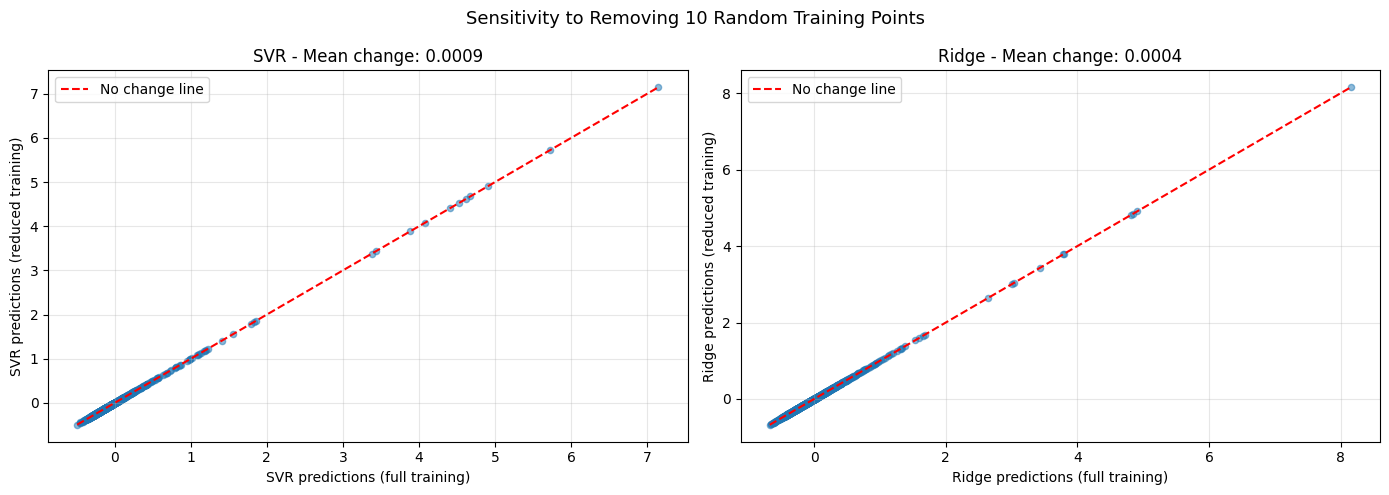

In [ ]:
# Plotting prediction changes
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(y_pred_svr_full, y_pred_svr_reduced, alpha=0.5, s=20)
axes[0].plot([y_pred_svr_full.min(), y_pred_svr_full.max()],
             [y_pred_svr_full.min(), y_pred_svr_full.max()],
             'r--', label='No change line')
axes[0].set_xlabel("SVR predictions (full training)")
axes[0].set_ylabel("SVR predictions (reduced training)")
axes[0].set_title(f"SVR - Mean change: {svr_pred_change.mean():.4f}")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].scatter(y_pred_ridge_full, y_pred_ridge_reduced, alpha=0.5, s=20)
axes[1].plot([y_pred_ridge_full.min(), y_pred_ridge_full.max()],
             [y_pred_ridge_full.min(), y_pred_ridge_full.max()],
             'r--', label='No change line')
axes[1].set_xlabel("Ridge predictions (full training)")
axes[1].set_ylabel("Ridge predictions (reduced training)")
axes[1].set_title(f"Ridge - Mean change: {ridge_pred_change.mean():.4f}")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.suptitle("Sensitivity to Removing 10 Random Training Points", fontsize=13)
plt.tight_layout()
plt.show()

While both models are remarkably stable, Ridge is more stable than SVR when 10 training points are removed because its mean prediction change (0.0004) is less than half that of the SVR pipeline (0.0009), and its largest change is much smaller (0.004 vs 0.0175). This can be seen in the graphs above, where the points for the Ridge model are tighter together on the no-change line. Ridge Regression is less sensitive to the removal of training data because every training point contributes a small amount to the solution, and its tuning parameter (alpha = 100) is specifically designed to stabilize the inverse matrix. SVR's solution depends exclusively on its support vectors, so if a removed point was a support vector, the fitted function shifts more for certain predictions.

Note - both frameworks were refit on unscaled Drift using tuned hyperparameters (SVR linear kernel, C = 10, Ridge, alpha = 100), so the full-training R^2 values differ slightly from section 3 because in section 3, the target was standardized. Both models are treated the same way though, so the comparison is still fair/valid.

## 6. Collaboration Reflection (5 points)

As a group, identify **one specific challenge or inefficiency** you encountered while working on this lab. In 3–5 sentences:

1. Briefly describe what happened and how it affected your work.
2. Identify one concrete action your group will take to avoid or better manage this issue in the next lab.

If your group encountered no major problem, identify one aspect of your collaboration that could still be improved.

One specific challenge that occurred while we worked on this lab was conflicting schedules and exams. It's beginning to be midterm season, so we had to juggle doing work on this lab with studying and going to exams. This made it a bit more difficult to get certain parts of the work done as we had to focus on it while also keeping in mind exam material and such. A way around this is trying to designate time around exams and classes specifically, planning meetings and/or discussions on parts of the lab when necessary.